In [1]:
import os, sys
sys.path.append(os.path.dirname(os.path.abspath('')))
from src.paths import get_results_dir
RESULTS_DIR, DATA_DIR = get_results_dir()

path = os.path.dirname(os.path.dirname(RESULTS_DIR))+"/data/001201/sub-Monkey-N/sub-Monkey-N_ses-20210503_ecephys.nwb"
from pynwb import NWBHDF5IO
io = NWBHDF5IO(path, "r")
nwbfile = io.read()
print(nwbfile)

root pynwb.file.NWBFile at 0x134991639213936
Fields:
  analysis: {
    SpikingBandPower <class 'pynwb.ecephys.ElectricalSeries'>,
    ThresholdCrossings <class 'pynwb.ecephys.ElectricalSeries'>,
    index_position <class 'pynwb.base.TimeSeries'>,
    index_velocity <class 'pynwb.base.TimeSeries'>,
    mrs_position <class 'pynwb.base.TimeSeries'>,
    mrs_velocity <class 'pynwb.base.TimeSeries'>
  }
  devices: {
    Lateral <class 'pynwb.device.Device'>,
    Medial <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    Lateral <class 'pynwb.ecephys.ElectrodeGroup'>,
    Medial <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'hdmf.common.table.DynamicTable'>
  experiment_description: Behavioral and neural data from Utah Array recordings from a macaque doing finger movements
  experimenter: ['Chestek Lab']
  file_create_date: [datetime.datetime(2025, 10, 3, 16, 20, 54, 959064, tzinfo=tzutc())]
  identifier: 2021-05-03_CO_nwb
  institution: University of Mic

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.ndimage import gaussian_filter1d
import os
import pickle

# Index flexion position, from fully extended (0) to fully flexed (1)
# Middle-ring-pinky flexion position, from fully extended (0) to fully flexed (1)
# Velocity of index flexion
# Velocity of middle-ring-pinky flexion
# Spiking Band Power across time, in 20ms bins
# Threshold crossings (threshold = -4.5RMS) across time, in 20ms bins

In [3]:
fs = 50  # Sampling frequency
cutoff = 8  # Cutoff frequency
order = 5  # Filter order
b, a = signal.butter(order, cutoff, btype='low', fs=fs)

def extract_data(path):
    
    sum_count_train = 0
    sum_count_test = 0

    counts = []
    index_target_position_trials = []
    mrs_target_position_trials = []
    target_style_trials = []

    starts = []
    with NWBHDF5IO(path, "r") as io:
        nwbfile_live = io.read()
        assert len(nwbfile_live.trials) == 375
        
        index_position = np.array(nwbfile_live.trials[0]["timeseries"][0][0].timeseries.data).squeeze()
        
        for trial_idx in range(375):
            row = nwbfile_live.trials[trial_idx]
            count = row["timeseries"][trial_idx][3].count
            start = row["timeseries"][trial_idx][3].idx_start
            
            index_target_position_trials.append(row["index_target_position"][trial_idx])
            mrs_target_position_trials.append(row["mrs_target_position"][trial_idx])
            target_style_trials.append(row["target_style"][trial_idx])
            starts.append(start)

            if trial_idx < 300:
                sum_count_train += count+1
            else:
                sum_count_test += count+1
            counts.append(count+1)
        
    position_shift_train = index_position[:sum_count_train].mean()
    position_scale_train = index_position[:sum_count_train].std()
        
    index_position_train_trials = []
    mrs_position_train_trials = []
    index_velocity_train_trials = []
    mrs_velocity_train_trials = []
    spiking_band_power_train_trials = []
    threshold_crossings_train_trials = []
    index_target_position_train_trials = []
    mrs_target_position_train_trials = []
    target_style_train_trials = []

    index_position_test_trials = []
    mrs_position_test_trials = []
    index_velocity_test_trials = []
    mrs_velocity_test_trials = []
    spiking_band_power_test_trials = []
    threshold_crossings_test_trials = []
    index_target_position_test_trials = []
    mrs_target_position_test_trials = []
    target_style_test_trials = []

    index_target_position = np.concatenate([[index_target_position_trials[i]] * counts[i] for i in range(375)])
    mrs_target_position = np.concatenate([[mrs_target_position_trials[i]] * counts[i] for i in range(375)])

    with NWBHDF5IO(path, "r") as io:
        nwbfile_live = io.read()
        mrs_position  = np.array(nwbfile_live.trials[0]["timeseries"][0][1].timeseries.data).squeeze()
        index_velocity = np.array(nwbfile_live.trials[0]["timeseries"][0][2].timeseries.data)
        mrs_velocity  = np.array(nwbfile_live.trials[0]["timeseries"][0][3].timeseries.data)
        spiking_band_power = np.array(nwbfile_live.trials[0]["timeseries"][0][4].timeseries.data)
        threshold_crossings = np.array(nwbfile_live.trials[0]["timeseries"][0][5].timeseries.data)
        t = np.array(nwbfile_live.trials[0]["timeseries"][0][0].timeseries.timestamps)
        
        assert sum_count_train + sum_count_test == index_position.shape[0] == mrs_position.shape[0] == index_velocity.shape[0] == mrs_velocity.shape[0] == spiking_band_power.shape[0] == threshold_crossings.shape[0]
        print(t.shape, mrs_position .shape, index_position.shape, spiking_band_power.shape)

        print(f"Train Set Cut Off: {sum_count_train} samples, {sum_count_train/index_position.shape[0]:.2f} of total samples")
        print(f"Test Set Cut Off: {sum_count_test} samples, {sum_count_test/index_position.shape[0]:.2f} of total samples")

        # train set
        spiking_band_power_train =  signal.filtfilt(b, a, spiking_band_power[:sum_count_train], axis=0)
        spiking_band_power_shift = spiking_band_power_train.mean(axis=0)
        spiking_band_power_scale = spiking_band_power_train.std(axis=0)
        spiking_band_power_train = (spiking_band_power_train - spiking_band_power_shift) / spiking_band_power_scale

        index_position_train = index_position[:sum_count_train]
        index_position_train = gaussian_filter1d(index_position_train, sigma=8, axis=0)
        index_position_train = (index_position_train - position_shift_train) / position_scale_train
        mrs_position_train = mrs_position[:sum_count_train]
        mrs_position_train = gaussian_filter1d(mrs_position_train, sigma=8, axis=0)
        mrs_position_train = (mrs_position_train - position_shift_train) / position_scale_train
        
        index_velocity_train = gaussian_filter1d(index_velocity[:sum_count_train], sigma=8, axis=0) / position_scale_train
        mrs_velocity_train = gaussian_filter1d(mrs_velocity[:sum_count_train], sigma=8, axis=0) / position_scale_train
        threshold_crossings_train = threshold_crossings[:sum_count_train]

        index_target_position_train = index_target_position[:sum_count_train]
        index_target_position_train = (index_target_position_train - position_shift_train) / position_scale_train
        mrs_target_position_train = mrs_target_position[:sum_count_train]
        mrs_target_position_train = (mrs_target_position_train - position_shift_train) / position_scale_train
        
        # test set
        spiking_band_power_test =  signal.filtfilt(b, a, spiking_band_power[sum_count_train:], axis=0)
        spiking_band_power_test = (spiking_band_power_test - spiking_band_power_shift) / spiking_band_power_scale

        index_position_test = index_position[sum_count_train:]
        index_position_test = gaussian_filter1d(index_position_test, sigma=8, axis=0)
        index_position_test = (index_position_test - position_shift_train) / position_scale_train
        mrs_position_test = mrs_position[sum_count_train:]
        mrs_position_test = gaussian_filter1d(mrs_position_test, sigma=8, axis=0)
        mrs_position_test = (mrs_position_test - position_shift_train) / position_scale_train
        index_velocity_test = gaussian_filter1d(index_velocity[sum_count_train:], sigma=8, axis=0) / position_scale_train
        mrs_velocity_test = gaussian_filter1d(mrs_velocity[sum_count_train:], sigma=8, axis=0) / position_scale_train
        threshold_crossings_test = threshold_crossings[sum_count_train:]

        index_target_position_test = index_target_position[sum_count_train:]
        mrs_target_position_test = mrs_target_position[sum_count_train:]
        index_target_position_test = (index_target_position_test - position_shift_train) / position_scale_train
        mrs_target_position_test = (mrs_target_position_test - position_shift_train) / position_scale_train

        for trial_idx in range(300):
            row = nwbfile_live.trials[trial_idx]
            start = row["timeseries"][trial_idx][3].idx_start
            count = row["timeseries"][trial_idx][3].count

            index_position_train_trials.append(index_position_train[start:start+count+1])
            mrs_position_train_trials.append(mrs_position_train[start:start+count+1])
            index_velocity_train_trials.append(index_velocity_train[start:start+count+1])
            mrs_velocity_train_trials.append(mrs_velocity_train[start:start+count+1])
            spiking_band_power_train_trials.append(spiking_band_power_train[start:start+count+1])
            threshold_crossings_train_trials.append(threshold_crossings_train[start:start+count+1])
            index_target_position_train_trials.append(index_target_position_train[start:start+count+1])
            mrs_target_position_train_trials.append(mrs_target_position_train[start:start+count+1])
            target_style_train_trials.append(target_style_trials[trial_idx])
            
            
        for trial_idx in range(300, 375):
            row = nwbfile_live.trials[trial_idx]
            start = row["timeseries"][trial_idx][3].idx_start
            count = row["timeseries"][trial_idx][3].count
            start = start - sum_count_train

            index_position_test_trials.append(index_position_test[start:start+count+1])
            mrs_position_test_trials.append(mrs_position_test[start:start+count+1])
            index_velocity_test_trials.append(index_velocity_test[start:start+count+1])
            mrs_velocity_test_trials.append(mrs_velocity_test[start:start+count+1])
            spiking_band_power_test_trials.append(spiking_band_power_test[start:start+count+1])
            threshold_crossings_test_trials.append(threshold_crossings_test[start:start+count+1])
            index_target_position_test_trials.append(index_target_position_test[start:start+count+1])
            mrs_target_position_test_trials.append(mrs_target_position_test[start:start+count+1])
            target_style_test_trials.append(target_style_trials[trial_idx])
    
    return (index_position_train,
            mrs_position_train,
            index_velocity_train,
            mrs_velocity_train,
            spiking_band_power_train,
            threshold_crossings_train,
            index_target_position_train,
            mrs_target_position_train,
            target_style_train_trials,
            index_position_test,
            mrs_position_test,
            index_velocity_test,
            mrs_velocity_test,
            spiking_band_power_test,
            threshold_crossings_test,
            index_target_position_test,
            mrs_target_position_test,
            target_style_test_trials
            )

## Saving

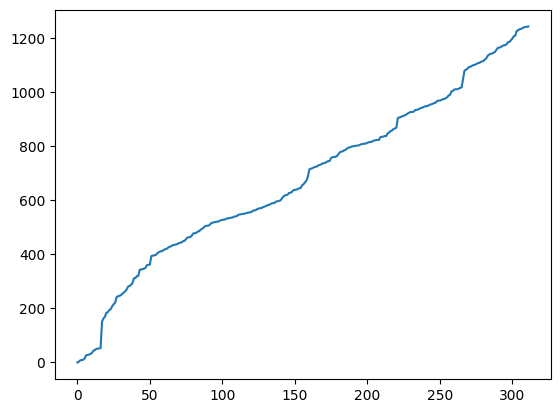

In [4]:
import pandas as pd
all_files = os.listdir(os.path.dirname(os.path.dirname(RESULTS_DIR))+"/data/001201/sub-Monkey-N/")
days = []
for file in all_files:
    # extract date from filename which is the 6 digit number after "ses-"
    date = file.split("ses-")[1].split("_")[0]
    # format date from YYYYMMDD to YYYY-MM-DD
    date = f"{date[:4]}-{date[4:6]}-{date[6:]}"
    # days since first date
    day = (pd.to_datetime(date) - pd.to_datetime("2020-01-27")).days
    days.append(day)
plt.plot(np.sort(days))

In [ ]:
seq_len = 200

all_files = os.listdir(os.path.dirname(os.path.dirname(RESULTS_DIR))+"/data/001201/sub-Monkey-N/")

rng = np.random.default_rng(0)
counter = 0
while counter < 25:
        file = all_files[rng.integers(len(all_files))]
        if "obj" in file: continue
        
        date = file.split("ses-")[1].split("_")[0]
        date = f"{date[:4]}-{date[4:6]}-{date[6:]}"
        day = (pd.to_datetime(date) - pd.to_datetime("2020-01-27")).days
        print(file, day)
        path = os.path.join(os.path.dirname(os.path.dirname(RESULTS_DIR)), "data/001201/sub-Monkey-N/", file)

        (index_position_train,
                mrs_position_train,
                index_velocity_train,
                mrs_velocity_train,
                spiking_band_power_train,
                threshold_crossings_train,
                index_target_position_train,
                mrs_target_position_train,
                target_style_train_trials,
                index_position_test,
                mrs_position_test,
                index_velocity_test,
                mrs_velocity_test,
                spiking_band_power_test,
                threshold_crossings_test,
                index_target_position_test,
                mrs_target_position_test,
                target_style_test_trials) = extract_data(path)

        if len(np.unique(target_style_test_trials))>1 or np.unique(target_style_test_trials)[0] != "RD":
                continue        

        n_chunks_train = spiking_band_power_train.shape[0] // seq_len
        n_chunks_test = spiking_band_power_test.shape[0] // seq_len

        save_path = DATA_DIR + "/mc_multitask/" + file.replace("_ecephys.nwb", "").replace("sub-Monkey-N_ses-", "")

        spiking_chunks_train = [spiking_band_power_train[i:i+seq_len] for i in range(0, n_chunks_train * seq_len, seq_len)]
        spiking_chunks_test = [spiking_band_power_test[i:i+seq_len] for i in range(0, n_chunks_test * seq_len, seq_len)]

        finger_position_chunks_train = [np.stack([index_position_train[i:i+seq_len], mrs_position_train[i:i+seq_len]], axis=1) for i in range(0, n_chunks_train * seq_len, seq_len)]
        finger_position_chunks_test = [np.stack([index_position_test[i:i+seq_len], mrs_position_test[i:i+seq_len]], axis=1) for i in range(0, n_chunks_test * seq_len, seq_len)]

        finger_target_position_chunks_train = [np.stack([index_target_position_train[i:i+seq_len], mrs_target_position_train[i:i+seq_len]], axis=1) for i in range(0, n_chunks_train * seq_len, seq_len)]
        finger_target_position_chunks_test = [np.stack([index_target_position_test[i:i+seq_len], mrs_target_position_test[i:i+seq_len]], axis=1) for i in range(0, n_chunks_test * seq_len, seq_len)]

        # train set
        os.makedirs(f"{save_path}/observations", exist_ok=True)
        os.makedirs(f"{save_path}/externals", exist_ok=True)
        with open(f"{save_path}/observations/1_spikes.pkl", "wb") as f:
                pickle.dump(spiking_chunks_train, f)
        with open(f"{save_path}/observations/2_finger_position.pkl", "wb") as f:
                pickle.dump(finger_position_chunks_train, f)

        with open(f"{save_path}/externals/target_position.pkl", "wb") as f:
                pickle.dump(finger_target_position_chunks_train, f)
                
        # test set
        os.makedirs(f"{save_path}_test/observations", exist_ok=True)
        os.makedirs(f"{save_path}_test/externals", exist_ok=True)
        with open(f"{save_path}_test/observations/1_spikes.pkl", "wb") as f:
                pickle.dump(spiking_chunks_test, f)
        with open(f"{save_path}_test/observations/2_finger_position.pkl", "wb") as f:
                pickle.dump(finger_position_chunks_test, f)

        with open(f"{save_path}_test/externals/target_position.pkl", "wb") as f:
                pickle.dump(finger_target_position_chunks_test, f)
                
        counter += 1      


In [ ]:
len(spiking_chunks_train), len(finger_position_chunks_train), len(finger_target_position_chunks_train), len(spiking_chunks_test), len(finger_position_chunks_test), len(finger_target_position_chunks_test)

(98, 98, 98, 24, 24, 24)

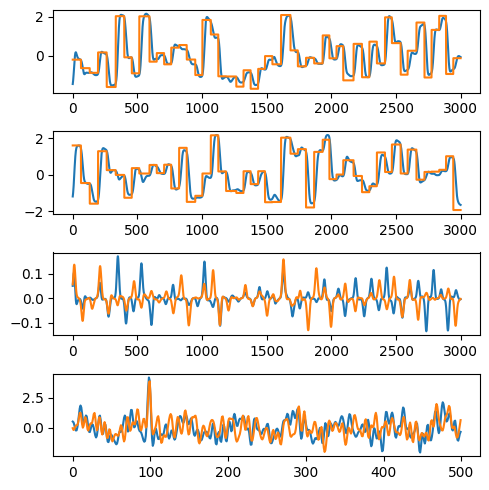

In [ ]:
#plt.hist(counts, bins=20)
#plt.show()

idx_start = rng.integers(0, index_position_test.shape[0]-3000)
fig, axs = plt.subplots(4, 1, figsize=(5, 5))

axs[0].plot(index_position_test[idx_start:idx_start+3000])
axs[0].plot(index_target_position_test[idx_start:idx_start+3000])

axs[1].plot(mrs_position_test[idx_start:idx_start+3000])
axs[1].plot(mrs_target_position_test[idx_start:idx_start+3000])

axs[2].plot(index_velocity_test[idx_start:idx_start+3000])
axs[2].plot(mrs_velocity_test[idx_start:idx_start+3000])

axs[3].plot(spiking_band_power_test[idx_start:idx_start+500, :2])
#axs[3].plot(threshold_crossings_test[idx_start:idx_start+3000, :2])
plt.tight_layout()
plt.show()